# 04 · Aprendizaje por refuerzo sobre el entorno `agent.py` (Reto 4)

**Objetivo de negocio:** comprobar si un agente que **aprende en línea** (probando
recomendaciones y observando si el usuario termina la película) descubre por sí mismo qué
combinaciones de edad y género hay que evitar, cuánto tarda en descubrirlo y cuánto mejora
frente al recomendador estático del reto 2. Es la vía para obtener preferencias que el
histórico no contiene (notebook 00, *Estructura de preferencias*) y complementa al
Random Forest del reto 3, que solo puede detectar el segmento offline.

**Objetivo técnico:** se corrige `agent.py` **sin modificarlo** (`src/rl_env.py`: sólo los
dos bugs reales), se plantea un **bandit contextual** (episodios de 1 paso; estado = grupo
de edad), se deriva la **política óptima analítica** de las probabilidades del simulador,
se entrena **Q-learning tabular** ε-greedy (más UCB como referencia) con ≥ 5 semillas y se
compara con política aleatoria, recomendador híbrido sin RL y óptimo, midiendo **regret
acumulado**, **convergencia** y **tiempo de descubrimiento**.

**Nota sobre las cifras:** las cifras citadas en el texto son las de la **ejecución completa**
(`full`: 100.000 interacciones, 10 semillas). Con `NP_FAST=1` (20.000 interacciones, 3
semillas, interacciones del 10 % de los usuarios) varían y valen las salidas de las celdas.

## Requisitos

- **Local:** Python ≥ 3.11 y `pip install -r requirements.txt` (o `python harness/init.py --install`, que crea el `.venv`).
- **Colab:** la celda de instalación de más abajo ejecuta `%pip install -q paquete==versión` **solo para lo que falte** (versión fijada). No se reinstalan `numpy`, `pandas`, `scikit-learn`, `matplotlib` ni `torch`: Colab ya los trae y cambiarlos obliga a reiniciar el entorno, lo que rompe «Ejecutar todo». Si no hay `data/raw`, la primera celda clona el repositorio público (o usa `NilePrime_AliGuerrero_codigo.zip` en `/content`).
- **Librerías de este notebook (versión de `requirements.txt`):** `pandas==2.3.3`, `numpy==2.3.5`, `scipy==1.18.1`, `matplotlib==3.10.6`.

In [1]:
# Entorno: Colab o local y raíz del proyecto sin rutas absolutas (la instalación va en la celda siguiente).
REPO_URL = "https://github.com/aliguerreroj/nile-prime-ia.git"  # repositorio público con código y datos
ZIP_NAME = "NilePrime_AliGuerrero_codigo.zip"  # alternativa sin GitHub: subirlo a /content

import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
FAST = os.environ.get("NP_FAST") == "1"
SEED = 42

# Raíz = primera carpeta (cwd o sus padres) que contiene data/raw.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw").is_dir()),
    None,
)
if RAIZ is None and EN_COLAB:
    # Colab: (a) zip en /content, (b) si no hay zip, git clone del repositorio público.
    import subprocess
    import zipfile

    _base = Path("/content")

    def _buscar_raiz():
        """Rutas directas primero; rglob solo como último recurso (sin recorrer /content/drive)."""
        for _d in (_base / "nile-prime-ia", _base / "NilePrime_AliGuerrero_codigo", _base):
            if (_d / "data" / "raw").is_dir():
                return _d
        for _sub in sorted(_base.iterdir()):
            if _sub.is_dir() and _sub.name not in ("drive", "sample_data"):
                for _raw in sorted(_sub.rglob("raw")):
                    if _raw.parent.name == "data" and _raw.is_dir():
                        return _raw.parent.parent
        return None

    for _z in sorted(_base.glob("NilePrime*codigo*.zip")) or sorted(_base.glob("*.zip")):
        with zipfile.ZipFile(_z) as _f:
            if any("data/raw/" in n for n in _f.namelist()):
                _f.extractall(_base)
                break
    RAIZ = _buscar_raiz()
    if RAIZ is None:
        try:
            _git = subprocess.run(["git", "clone", "--depth", "1", REPO_URL], cwd=_base,
                                  check=False, capture_output=True, text=True)
            _err = (_git.stderr or _git.stdout or "").strip().splitlines()
        except OSError as _e:
            _err = [str(_e)]
        RAIZ = _buscar_raiz()
        if RAIZ is None:
            raise RuntimeError(
                "No se pudo obtener el proyecto en Colab. Opción 1: comprueba la conexión a "
                "internet y vuelve a ejecutar (se clona " + REPO_URL + "). Opción 2: sube "
                + ZIP_NAME + " a /content y vuelve a ejecutar. Último error de git: "
                + (_err[-1] if _err else "sin salida")
            )
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra data/raw: ejecuta el notebook desde la carpeta del proyecto o una subcarpeta."
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

In [2]:
# Instalación de dependencias (solo Colab, solo lo que falte; en local no instala nada).
# Colab ya trae todo lo demás; scipy se comprueba por si acaso.
import importlib.util

# paquete pip -> (módulo importable, versión fijada en requirements.txt)
_REQUISITOS = {"scipy": ("scipy", "1.18.1")}
_faltan = [f"{p}=={v}" for p, (m, v) in _REQUISITOS.items() if importlib.util.find_spec(m) is None]
if EN_COLAB and _faltan:
    for _spec in _faltan:
        # Equivalente a la magia:  %pip install -q scipy==1.18.1
        # (se usa run_line_magic porque jupytext no descomenta magias dentro de un bloque `if`).
        get_ipython().run_line_magic("pip", f"install -q {_spec}")  # noqa: F821
    print("Instalado:", ", ".join(_faltan))
else:
    print("Nada que instalar" + ("" if EN_COLAB else " (entorno local: usa requirements.txt)"))

Nada que instalar (entorno local: usa requirements.txt)


In [3]:
# Imports, semilla y configuración común.
import inspect
import json
import time
import warnings
from contextlib import contextmanager

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

from src import data, plots, rl_env as R
from src.stats import wilson_ci

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
np.random.seed(SEED)
plots.set_style()
PAL = plots.PALETA
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

MODO = "fast" if FAST else "full"
T_FINAL = 20_000 if FAST else 100_000          # interacciones (episodios de 1 paso) por semilla
SEMILLAS = list(range(3 if FAST else 10))      # semillas de evaluación final (>= 5 en full)
SEM_AJUSTE = list(range(100, 103 if FAST else 105))  # semillas de ajuste de hiperparámetros
T_AJUSTE = T_FINAL // 3
VENT_CURVA = 1000 if FAST else 2000            # ventana de la media móvil y de convergencia
VENT_FINAL = 2000 if FAST else 5000            # ventana para la recompensa "final"
N_MC = 3000 if FAST else 6000                # pasos de la comprobación Monte Carlo
K_RERANK = 10                                  # candidatos del recomendador híbrido
print(f"Modo: {MODO} | SEED = {SEED} | Colab: {EN_COLAB}")
print(f"T = {T_FINAL:,} interacciones | semillas finales = {SEMILLAS} | "
      f"semillas de ajuste = {SEM_AJUSTE} | ventana = {VENT_CURVA}")
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

TIEMPOS: dict[str, float] = {}


@contextmanager
def seccion(nombre: str):
    """Mide el tiempo de pared de una sección y lo guarda en ``TIEMPOS``."""
    t0 = time.perf_counter()
    yield
    TIEMPOS[nombre] = round(time.perf_counter() - t0, 1)


def nativo(o):
    """Convierte tipos de numpy a tipos nativos de Python para json."""
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(type(o))


def ms(x, d: int = 4) -> str:
    """Formatea la media ± desviación estándar de un vector entre semillas."""
    x = np.asarray(x, dtype=float)
    return f"{np.nanmean(x):.{d}f} ± {np.nanstd(x, ddof=1) if len(x) > 1 else 0:.{d}f}"


def ms_t(x) -> str:
    """Media ± sd de tiempos de descubrimiento, con nº de semillas que lo alcanzan."""
    x = np.asarray(x, dtype=float)
    ok = ~np.isnan(x)
    if not ok.any():
        return f"no alcanzado (0/{len(x)})"
    sd = x[ok].std(ddof=1) if ok.sum() > 1 else 0.0
    return f"{x[ok].mean():,.0f} ± {sd:,.0f} ({ok.sum()}/{len(x)})"

Modo: full | SEED = 42 | Colab: False
T = 100,000 interacciones | semillas finales = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | semillas de ajuste = [100, 101, 102, 103, 104] | ventana = 2000
numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1


## 1. El entorno del profesor: dos bugs reales y una regla que NO es un bug

**Qué:** importar `agent.py` (que no se toca) y demostrar su comportamiento tal cual.
`agent.py` lee `./Metadatos Películas.csv` y `./interacciones.csv` del directorio actual al
importarse; los CSV viven en `data/raw` con tildes en Unicode NFD, así que
`R.cargar_entorno_original()` carga el módulo por ruta y, sólo durante la importación,
sustituye `pandas.read_csv` por una función que resuelve esos nombres con `glob`
(se restaura en un `finally`; sin `chdir` ni rutas absolutas; vale en Colab). Un test
comprueba el sha256 de `agent.py`.

**Bugs reales** (se muestran dentro de `try/except` para que el notebook no falle):
1. `step()` llama a `self._get_state()`, que **no existe** → `AttributeError`.
2. `reset()` muestrea un usuario pero **no devuelve nada** (`None`), de modo que el agente
   no puede observar el estado.

**No es un bug:** `_simulate_user_watch` compara el género **exacto** (`.get(movie_genre, 0)`
sobre la cadena completa de `Genre`). Así penaliza `"Drama"` pero no `"Drama, Romance"`.
Es, además, la regla con la que se generó `interacciones.csv` (sección 1.2), por lo que
`modo="original"` la conserva. Tampoco se toca el valor por defecto 0,8, que nunca se usa
(los tres grupos están en el diccionario).

In [4]:
with seccion("1_entorno"):
    agent = R.cargar_entorno_original()
    META = data.load_metadata()                                  # 1.000 filas, movie_id = posición
    INTER = data.load_interactions(sin_duplicados=True)          # submuestra si NP_FAST=1
    print(f"Catálogo: {len(META)} películas | interacciones: {len(INTER):,} filas, "
          f"{INTER['User_ID'].nunique():,} usuarios")
    print("sha256(agent.py) coincide con el esperado:", R.sha256_agent() == R.SHA256_AGENT)

    env_prof = agent.SimulationEnvironment(META, INTER)
    print("\n--- Bug 2: reset() del profesor ---")
    estado = env_prof.reset()
    print(f"reset() devuelve: {estado!r}  (el usuario sí se guarda en env.current_user: "
          f"grupo = {env_prof.current_user['Age_Group']})")
    print("\n--- Bug 1: step() del profesor ---")
    try:
        env_prof.step(0)
    except Exception as e:  # noqa: BLE001 - se muestra el tipo y el mensaje a propósito
        print(f"{type(e).__name__}: {e}")

Catálogo: 1000 películas | interacciones: 100,623 filas, 10,000 usuarios
sha256(agent.py) coincide con el esperado: True

--- Bug 2: reset() del profesor ---
reset() devuelve: None  (el usuario sí se guarda en env.current_user: grupo = adults)

--- Bug 1: step() del profesor ---
AttributeError: 'SimulationEnvironment' object has no attribute '_get_state'


### 1.1 Cambios de `NilePrimeEnv` respecto a `agent.py`

`NilePrimeEnv` **hereda** de `SimulationEnvironment`: `step()` y la lógica de recompensa son
las del profesor; sólo se añade lo necesario.

| N.º | Cambio | Motivo |
|---|---|---|
| 1 | `_get_state()` devuelve el índice del grupo de edad (`youth`=0, `adults`=1, `seniors`=2) | no existía: `step()` fallaba (bug real) |
| 2 | `reset()` devuelve el estado | devolvía `None` (bug real) |
| 3 | `reset()` pone `done = False` | `done` quedaba en `True` tras el primer `step` |
| 4 | Generador propio `np.random.RandomState(seed)` en lugar del global | reproducibilidad; es el **mismo generador** que `np.random.rand`, así que con la misma semilla las decisiones son idénticas a las del profesor (test) |
| 5 | Parámetro `modo`: `original` (defecto), `contiene`, `calibrado` | análisis de sensibilidad; `original` = regla exacta del profesor |

La recompensa (1 si ve la película completa, 0 si no) y la probabilidad de `original` no
cambian. Un test recupera por bisección la probabilidad del código del profesor para cada
género y grupo y comprueba que coincide con la matriz `P` que usa el notebook.

In [5]:
with seccion("1_entorno_nile"):
    env = R.NilePrimeEnv(META, INTER, modo="original", seed=SEED)
    print("Demostración de NilePrimeEnv (modo original), 5 episodios con acciones al azar:")
    rng_demo = np.random.default_rng(SEED)
    for _ in range(5):
        s = env.reset()
        a = int(rng_demo.integers(0, len(META)))
        s2, r, done = env.step(a)
        print(f"  estado={R.GRUPOS[s]:8s} acción={a:4d} género={META.loc[a, 'Genre']:<24s} "
              f"recompensa={r} done={done}")

Demostración de NilePrimeEnv (modo original), 5 episodios con acciones al azar:
  estado=adults   acción=  89 género=Drama                    recompensa=1 done=True
  estado=seniors  acción= 773 género=Drama, Romance           recompensa=1 done=True
  estado=seniors  acción= 654 género=Drama, Sci-Fi, Thriller  recompensa=1 done=True
  estado=seniors  acción= 438 género=Crime, Drama, Film-Noir  recompensa=1 done=True
  estado=seniors  acción= 433 género=Drama                    recompensa=1 done=True


### 1.2 La comparación exacta es el proceso que generó los datos; simulador vs. datos

**Qué:** contrastar la regla del simulador con el abandono observado en `interacciones.csv`
(`Watched_to_End = False`), con IC de Wilson al 95 %. Si la regla exacta fuese un error del
profesor, los datos mostrarían penalización también en películas que *contienen* el género.

**Hallazgo (verificado):** youth × género **exactamente** Drama/Horror y seniors × **exactamente**
Comedy abandonan ≈ 21 % (frente a ≈ 10 % del resto); las películas que sólo *contienen* el
género **no** se penalizan. Además, no existe ninguna película con género exactamente
`Romance`, `Action` ni `Sci-Fi`, así que **adults nunca se penaliza**.

**Inconsistencias simulador vs. datos** (se declaran, no se corrigen en `original`):
el simulador da **0 %** de abandono fuera del segmento (datos ≈ 10 %) y penalizaciones de
**0,30 / 0,25** (datos ≈ 0,21).

In [6]:
with seccion("1_simulador_vs_datos"):
    full = data.load_interactions(sin_duplicados=True, rapido=False)
    cat_u = data.load_metadata(titulos_unicos=True)
    dm = full.merge(cat_u[["Series_Title", "Genre"]], on="Series_Title", how="left")
    dm["abandona"] = ~dm["Watched_to_End"].astype(bool)
    toks = dm["Genre"].str.split(", ")

    seg_exacto = np.zeros(len(dm), bool)
    seg_contiene = np.zeros(len(dm), bool)
    for g, pen in R.SEGMENTOS_PROFESOR.items():
        en_g = (dm["Age_Group"] == g).to_numpy()
        seg_exacto |= en_g & dm["Genre"].isin(pen).to_numpy()
        seg_contiene |= en_g & toks.apply(lambda t, p=pen: bool(set(t) & set(p))).to_numpy()
    grupos_tab = {
        "youth × Drama/Horror EXACTO": ((dm["Age_Group"] == "youth") & seg_exacto, 0.30),
        "seniors × Comedy/Romance EXACTO": ((dm["Age_Group"] == "seniors") & seg_exacto, 0.25),
        "adults × Action/Sci-Fi EXACTO": ((dm["Age_Group"] == "adults") & seg_exacto, 0.20),
        "solo CONTIENE el género (no exacto)": (seg_contiene & ~seg_exacto, 0.0),
        "resto (sin relación con el segmento)": (~seg_contiene, 0.0),
    }
    filas = []
    for nombre, (m, pen_sim) in grupos_tab.items():
        n, k = int(m.sum()), int(dm.loc[m, "abandona"].sum())
        lo, hi = wilson_ci(k, n) if n else (np.nan, np.nan)
        filas.append({"grupo": nombre, "n": n, "abandono_datos": k / n if n else np.nan,
                      "ic95_inf": lo, "ic95_sup": hi, "abandono_simulador_original": pen_sim})
    TAB_SIM = pd.DataFrame(filas)
    print(TAB_SIM.to_string(index=False))

    # Tasas de los datos para el modo "calibrado".
    base = float(dm.loc[~seg_contiene, "abandona"].mean())
    seg_y = float(dm.loc[grupos_tab["youth × Drama/Horror EXACTO"][0], "abandona"].mean())
    seg_s = float(dm.loc[grupos_tab["seniors × Comedy/Romance EXACTO"][0], "abandona"].mean())
    CALIB = {"base": round(base, 4),
             "segmento": {"youth": round(seg_y, 4), "adults": round((seg_y + seg_s) / 2, 4),
                          "seniors": round(seg_s, 4)}}
    print("\nTasas de abandono para el modo calibrado:", CALIB,
          "\n(adults no tiene películas con género exacto del segmento: su valor es irrelevante)")

                               grupo     n  abandono_datos  ic95_inf  ic95_sup  abandono_simulador_original
         youth × Drama/Horror EXACTO  2937          0.2060    0.1918    0.2210                       0.3000
     seniors × Comedy/Romance EXACTO   474          0.2110    0.1766    0.2500                       0.2500
       adults × Action/Sci-Fi EXACTO     0             NaN       NaN       NaN                       0.2000
 solo CONTIENE el género (no exacto) 39541          0.0994    0.0965    0.1024                       0.0000
resto (sin relación con el segmento) 57671          0.0985    0.0961    0.1009                       0.0000

Tasas de abandono para el modo calibrado: {'base': 0.0985, 'segmento': {'youth': 0.206, 'adults': 0.2085, 'seniors': 0.211}} 
(adults no tiene películas con género exacto del segmento: su valor es irrelevante)


**Conclusión técnica.** `agent.py` tiene exactamente dos bugs de ejecución; la comparación
exacta de género coincide con el proceso generador de los datos (youth × Drama/Horror exactos
y seniors × Comedy exacto ≈ 21 %; el resto ≈ 10 %, incluidas las películas que sólo contienen
el género), por lo que `modo="original"` la conserva. El simulador difiere de los datos en la
tasa base (0 % frente a ≈ 10 %) y en la magnitud de la penalización (0,30/0,25 frente a ≈ 0,21).

**Implicación de negocio:** el simulador es una simplificación del mundo real (nadie abandona
fuera del segmento); sus resultados indican *cómo aprende* un agente, no cuánta retención ganaría.

## 2. Modos del entorno, política óptima analítica y baselines

**Qué:** matriz `P[estado, acción]` = probabilidad de ver completa cada película, por modo:
- `original`: regla del profesor (género exacto).
- `contiene`: penaliza si `Genre` **contiene** algún género del segmento (análisis de
  sensibilidad; problema mucho más rico).
- `calibrado`: género exacto como el profesor pero con las tasas **de los datos**
  (base ≈ 9,9 %, segmento ≈ 21 %), calculadas en 1.2.

**Planteamiento: bandit contextual.** Cada episodio dura **1 paso**: `reset()` muestrea una
fila de interacciones (estado = grupo de edad del usuario), el agente recomienda una película
y recibe `r ∈ {0, 1}`; no hay estado siguiente. Por tanto γ es irrelevante y la actualización
de Q-learning se reduce a `Q[s,a] ← Q[s,a] + α·(r − Q[s,a])`.
La distribución de estados es la de las filas (youth 33,6 %, adults 33,6 %, seniors 32,9 %).

**Política óptima analítica:** con `P` conocida, `V*(s) = max_a P[s,a]`; las acciones a evitar
son las de `P[s,a] < V*(s)`. **Baselines:** (i) política aleatoria (valor esperado exacto
`mean_a P[s,a]`); (ii) **recomendador sin RL** = top-1 del híbrido del reto 2 (hiperparámetros
elegidos en el notebook 02) para el usuario muestreado; también se calcula el valor medio del
top-10 y el oráculo dentro del top-10. Todos son valores esperados **exactos** (no simulados).

In [7]:
with seccion("2_modos_y_baselines"):
    GF = INTER["Age_Group"].map({g: i for i, g in enumerate(R.GRUPOS)}).to_numpy()
    W_EST = np.bincount(GF, minlength=3) / len(GF)
    GENEROS = META["Genre"].to_numpy()
    IDS_GEN, GEN_UNICOS = R.agrupar_por_genero(GENEROS)

    P = {m: R.matriz_probabilidades(m, GENEROS, CALIB) for m in R.MODOS}
    PO = {m: R.politica_optima(P[m], W_EST) for m in R.MODOS}
    PG = {m: R.matriz_por_genero(P[m], IDS_GEN) for m in R.MODOS}      # P por género exacto
    POG = {m: R.politica_optima(PG[m], W_EST) for m in R.MODOS}

    # Recomendador híbrido (reto 2): hiperparámetros del notebook 02 si existe su JSON.
    # El notebook es independiente: si el JSON del notebook 02 no existe, usa valores por defecto
    # y lo registra en FUENTE_H ("json" o "defecto").
    ALPHA_H, POSITIVO_H, FUENTE_H = 0.5, "cualquiera", "defecto"
    try:
        cfg2 = json.loads((RAIZ / "reports" / "metrics" / "recomendador.json").read_text(encoding="utf-8"))
        ALPHA_H = float(cfg2["config"]["alpha_elegido"])
        POSITIVO_H = str(cfg2["config"]["definicion_positivo_elegida"])
        FUENTE_H = "json"
    except (OSError, KeyError, ValueError):
        pass
    print(f"Fuente de los hiperparámetros del híbrido: {FUENTE_H}")
    t0 = time.perf_counter()
    USUARIOS, TOPK_USU = R.topk_recomendador(cat_u, INTER, ALPHA_H, POSITIVO_H, k=K_RERANK)
    T_HIBRIDO = time.perf_counter() - t0
    TOPK_FILA = TOPK_USU[np.searchsorted(USUARIOS, INTER["User_ID"].to_numpy())]  # (filas, K)
    print(f"Híbrido (alpha = {ALPHA_H}, positivo = '{POSITIVO_H}'): top-{K_RERANK} para "
          f"{len(USUARIOS):,} usuarios en {T_HIBRIDO:.1f} s")

    VAL = {}
    for m in R.MODOS:
        p_top1 = P[m][GF, TOPK_FILA[:, 0]]
        p_topk = P[m][GF[:, None], TOPK_FILA]
        VAL[m] = {
            "azar": PO[m]["valor_azar_medio"], "optimo": PO[m]["valor_optimo_medio"],
            "hibrido_top1": float(p_top1.mean()),
            "hibrido_top1_por_grupo": [float(p_top1[GF == s].mean()) for s in range(3)],
            "hibrido_topk_medio": float(p_topk.mean()),
            "oraculo_topk": float(p_topk.max(axis=1).mean()),
            "azar_por_grupo": PO[m]["valor_azar"].tolist(),
            "n_evitar": [len(x) for x in PO[m]["evitar"]],
            "brecha": PO[m]["brecha"],
        }
    TAB = pd.DataFrame({
        m: {"películas a evitar (youth/adults/seniors)": "/".join(map(str, VAL[m]["n_evitar"])),
            "recompensa aleatoria": VAL[m]["azar"], "híbrido top-1 (sin RL)": VAL[m]["hibrido_top1"],
            "híbrido top-10 (medio)": VAL[m]["hibrido_topk_medio"],
            "oráculo dentro del top-10": VAL[m]["oraculo_topk"],
            "óptima analítica": VAL[m]["optimo"], "margen de mejora (óptima − azar)": VAL[m]["brecha"]}
        for m in R.MODOS})
    print(TAB.to_string())
    print("\nAzar por grupo (youth, adults, seniors):",
          {m: np.round(PO[m]["valor_azar"], 5).tolist() for m in R.MODOS})
    # ¿Qué porcentaje de los top-1 del híbrido es Drama exacto, por grupo, frente al catálogo?
    es_drama_top1 = GENEROS[TOPK_FILA[:, 0]] == "Drama"
    HIB_DRAMA = {"catalogo": float((GENEROS == "Drama").mean() * 100),
                 **{g: float(es_drama_top1[GF == i].mean() * 100) for i, g in enumerate(R.GRUPOS)}}
    print("\nTop-1 del híbrido que es Drama exacto (%): " +
          ", ".join(f"{k} {v:.1f}" for k, v in HIB_DRAMA.items()))
    print("Aleatoria original, fórmula: youth 1 − 0,3·87/1000 = "
          f"{1 - 0.3 * 87 / 1000:.5f}; seniors 1 − 0,25·13/1000 = {1 - 0.25 * 13 / 1000:.5f}; adults = 1")

Fuente de los hiperparámetros del híbrido: json


Híbrido (alpha = 0.5, positivo = 'cualquiera'): top-10 para 10,000 usuarios en 0.9 s
                                          original     contiene calibrado
películas a evitar (youth/adults/seniors)  87/0/13  741/227/310   87/0/13
recompensa aleatoria                        0.9902       0.8847    0.8979
híbrido top-1 (sin RL)                      0.9735       0.8691    0.8920
híbrido top-10 (medio)                      0.9738       0.8704    0.8921
oráculo dentro del top-10                   0.9990       0.9509    0.9011
óptima analítica                            1.0000       1.0000    0.9015
margen de mejora (óptima − azar)            0.0098       0.1153    0.0036

Azar por grupo (youth, adults, seniors): {'original': [0.9739, 1.0, 0.99675], 'contiene': [0.7777, 0.9546, 0.9225], 'calibrado': [0.89215, 0.9015, 0.90004]}

Top-1 del híbrido que es Drama exacto (%): catalogo 8.5, youth 26.1, adults 24.8, seniors 25.7
Aleatoria original, fórmula: youth 1 − 0,3·87/1000 = 0.97390; seniors

### 2.1 Equivalencia entre el entorno real y el simulador vectorizado

**Qué:** para entrenar con 10 semillas × 100.000 episodios no se puede llamar 3 M veces al
entorno del profesor (`DataFrame.sample` + `iloc` por paso). Como la recompensa es Bernoulli con
probabilidad `P[s,a]`, el simulador vectorizado (`R.entrenar_bandit`) es **equivalente**. Se
demuestra (i) en los tests (`P` coincide con el código del profesor y, con la misma semilla,
`NilePrimeEnv` toma las mismas decisiones) y (ii) aquí con una comprobación Monte Carlo corta:
recompensa media observada en el entorno real con acciones aleatorias frente a la esperada
según `P` en los mismos estados.

In [8]:
with seccion("2_montecarlo"):
    filas = []
    for m in R.MODOS:
        e = R.NilePrimeEnv(META, INTER, modo=m, seed=SEED)
        gen = np.random.default_rng(SEED)
        obs, esp = [], []
        for a in gen.integers(0, len(META), N_MC):
            s = e.reset()
            obs.append(e.step(int(a))[1])
            esp.append(P[m][s, a])
        obs, esp = np.array(obs), np.array(esp)
        z = (obs.mean() - esp.mean()) / np.sqrt((esp * (1 - esp)).sum()) * len(esp)
        filas.append({"modo": m, "pasos": N_MC, "recompensa_observada": obs.mean(),
                      "recompensa_esperada": esp.mean(), "z": z})
    print(pd.DataFrame(filas).to_string(index=False))
    print("|z| < 2 en todos los modos → el entorno real y P coinciden (tolerancia estadística).")

     modo  pasos  recompensa_observada  recompensa_esperada       z
 original   6000                0.9907               0.9908 -0.1280
 contiene   6000                0.8857               0.8872 -0.4245
calibrado   6000                0.8917               0.8981 -1.6415
|z| < 2 en todos los modos → el entorno real y P coinciden (tolerancia estadística).


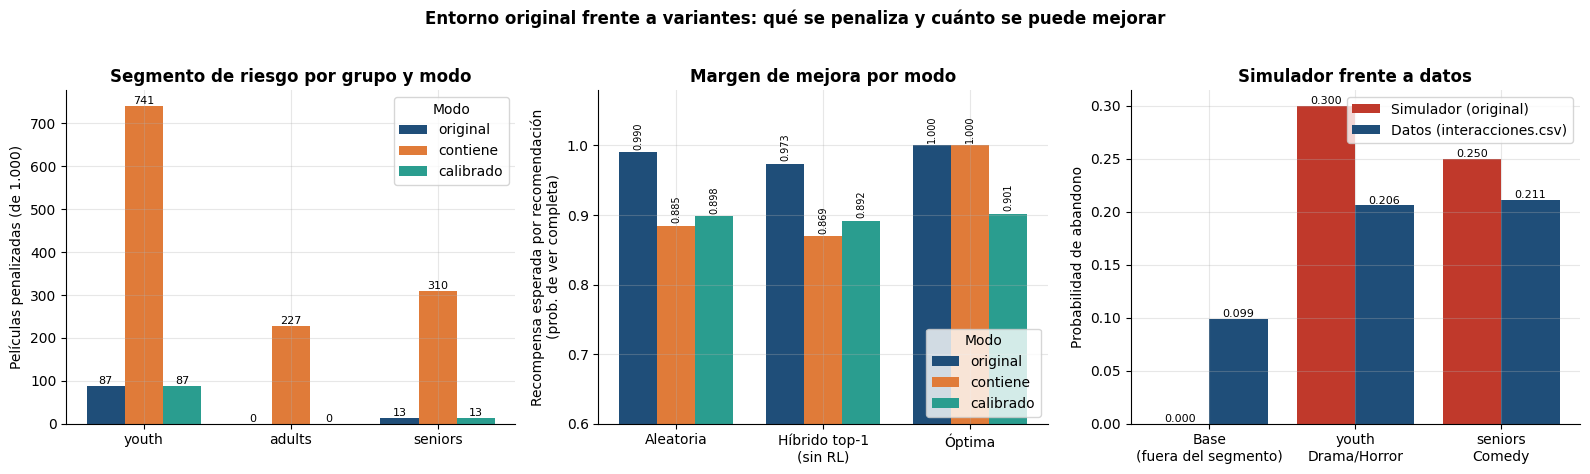

In [9]:
with seccion("2_figura_entorno"):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
    x = np.arange(3)
    ancho = 0.26
    cols = {"original": PAL["principal"], "contiene": PAL["enfasis"], "calibrado": PAL["edad_youth"]}
    for k, m in enumerate(R.MODOS):
        b = axs[0].bar(x + (k - 1) * ancho, VAL[m]["n_evitar"], ancho, label=m, color=cols[m])
        axs[0].bar_label(b, fontsize=8)
    axs[0].set_xticks(x, R.GRUPOS)
    axs[0].set_ylabel("Películas penalizadas (de 1.000)")
    axs[0].set_title("Segmento de riesgo por grupo y modo")
    axs[0].legend(title="Modo")

    nombres = ["azar", "hibrido_top1", "optimo"]
    etiquetas = ["Aleatoria", "Híbrido top-1\n(sin RL)", "Óptima"]
    for k, m in enumerate(R.MODOS):
        v = [VAL[m][n] for n in nombres]
        b = axs[1].bar(np.arange(3) + (k - 1) * ancho, v, ancho, label=m, color=cols[m])
        axs[1].bar_label(b, labels=[f"{y:.3f}" for y in v], fontsize=7, rotation=90, padding=2)
    axs[1].set_xticks(np.arange(3), etiquetas)
    axs[1].set_ylim(0.6, 1.08)
    axs[1].set_ylabel("Recompensa esperada por recomendación\n(prob. de ver completa)")
    axs[1].set_title("Margen de mejora por modo")
    axs[1].legend(title="Modo", loc="lower right")

    sim_vs = [("Base\n(fuera del segmento)", 0.0, CALIB["base"]),
              ("youth\nDrama/Horror", 0.30, CALIB["segmento"]["youth"]),
              ("seniors\nComedy", 0.25, CALIB["segmento"]["seniors"])]
    xs = np.arange(len(sim_vs))
    b1 = axs[2].bar(xs - 0.2, [s[1] for s in sim_vs], 0.4, label="Simulador (original)", color=PAL["referencia"])
    b2 = axs[2].bar(xs + 0.2, [s[2] for s in sim_vs], 0.4, label="Datos (interacciones.csv)", color=PAL["principal"])
    axs[2].bar_label(b1, fmt="%.3f", fontsize=8)
    axs[2].bar_label(b2, fmt="%.3f", fontsize=8)
    axs[2].set_xticks(xs, [s[0] for s in sim_vs])
    axs[2].set_ylabel("Probabilidad de abandono")
    axs[2].set_title("Simulador frente a datos")
    axs[2].legend()
    fig.suptitle("Entorno original frente a variantes: qué se penaliza y cuánto se puede mejorar",
                 fontweight="bold", y=1.02)
    fig.tight_layout()
    plots.save_fig(fig, "04_entorno_original_vs_corregido")
    plt.show()

**Conclusión técnica.** En `original` el problema es **casi trivial**: la política aleatoria
ya consigue 0,9739 (youth), 1,0 (adults) y 0,99675 (seniors) porque sólo 87 y 13 de 1.000
películas se penalizan (y ninguna para adults); la óptima vale 1,0 en los tres grupos y el
margen medio de mejora es ≈ 0,0098. Con `contiene` (741, 227 y 310 películas penalizadas) el
margen es ≈ 0,115 y con las tasas de los datos (`calibrado`) ≈ 0,0036: el escenario realista es
también el de menor margen y el más difícil de detectar. **El híbrido del reto 2 queda por
debajo del azar** (0,9735 frente a 0,9902 en `original`; para youth 0,9217 frente a 0,9739): su
top-1 es Drama exacto en ≈ 25 % de los casos de cada grupo (youth 26,1 %, adults 24,8 %, seniors
25,7 %; cifras calculadas arriba) frente a ≈ 8,5 % del catálogo, es decir, sobre-recomienda Drama
puro a **todos** los grupos; sólo youth lo paga, porque Drama puro es su segmento de riesgo. El
híbrido no se diseñó para esta recompensa (optimiza afinidad y popularidad), así que no es una
comparación contra un recomendador pensado para ella. Es el mismo patrón edad × género que el
Random Forest detecta offline en el reto 3.

**Implicación de negocio:** con la regla exacta del profesor el margen que el RL puede añadir
es pequeño en términos absolutos, pero el recomendador estático actual está **por debajo
del azar** para los jóvenes.

## 3. Agente, hiperparámetros y programa de exploración

**Agente:** Q-learning tabular. Estado = grupo de edad (3). Acción = película (**1.000
brazos por contexto**) como formulación principal, y como segunda formulación **re-ranking
del top-10 del híbrido** (el agente elige entre los 10 candidatos del usuario muestreado,
con Q por (estado, película)). Como ejes adicionales: (i) **UCB1** como referencia clásica de
bandit y (ii) un agente cuya acción es el **género exacto** (202 grupos), que muestra qué
pasa si la representación generaliza. Se descarta el DQN: con 3 estados el caso tabular es
exacto y es el primer escalón de la política de plazo.

**Decisiones (se eligen con datos en la rejilla de abajo, no a ojo):**
- **Inicialización de Q (`Q₀`)** ∈ {1; 0,5; 0}. `Q₀ = 1` es *optimista* (cota superior de la
  recompensa): cada película parece buena hasta que falla y el desempate aleatorio entre acciones
  empatadas explora de forma sistemática. Con `Q₀` bajo el agente explota la primera película
  que le funciona. Hay un trade-off real: casi todas las películas son óptimas (91-100 % según el
  modo), así que explorar sistemáticamente es caro en regret, pero es lo único que permite
  *saber* qué películas son de riesgo.
- **α**: constante 0,1 frente a `1/N(s,a)` (media muestral). En un entorno estacionario la media
  muestral es el estimador asintóticamente correcto, pero con `1/N` la primera observación
  *sobrescribe* `Q₀` (`Q ← r`), mientras que con α = 0,1 `Q₀` actúa como un *prior* con peso.
  Cuál rinde mejor en este horizonte es empírico: se decide con la rejilla.
- **Programa de ε** (`ε₀ = 0,3 → ε_min = 0,01`): constante en `ε₀` = 0,3, **exponencial** (llega a
  ε_min a mitad del entrenamiento) e **inverso** (`ε₀/(1+t/τ)`, con el mismo punto de llegada).
  Con ε constante el regret crece linealmente (explora para siempre); un decaimiento lo hace
  sublineal.

**Protocolo:** el ajuste usa **semillas distintas** (100-104) y **un tercio de las interacciones**
que la evaluación final (semillas 0-9), de modo que los números finales no se eligen mirándolos.
Criterio: regret acumulado normalizado por el de la política aleatoria (1 = tan malo como el
azar), promediado en los tres modos.

In [10]:
HORIZ = {m: PO[m]["brecha"] for m in R.MODOS}


def correr(m, eps_tipo, alpha, q0, semillas, T, P_use=None, **kw):
    """Entrena un agente en el modo ``m`` y devuelve ``(resultado, regret por paso)``."""
    Pm = P[m] if P_use is None else P_use
    r = R.entrenar_bandit(Pm, GF, semillas, T, R.programa_epsilon(eps_tipo, T), alpha=alpha, q0=q0, **kw)
    return r, R.regret_por_paso(r["esperada"], r["estados"], Pm)


with seccion("3_ajuste"):
    filas = []
    for eps_tipo in ["constante", "exponencial", "inverso"]:
        for alpha in [0.1, None]:
            for q0 in [1.0, 0.5, 0.0]:
                fila = {"epsilon": eps_tipo, "alpha": "0.1" if alpha else "1/N", "q0": q0}
                for m in R.MODOS:
                    _, reg = correr(m, eps_tipo, alpha, q0, SEM_AJUSTE, T_AJUSTE)
                    fila[f"regret_rel_{m}"] = reg.sum(axis=1).mean() / (HORIZ[m] * T_AJUSTE)
                filas.append(fila)
    AJ = pd.DataFrame(filas)
    AJ["regret_rel_medio"] = AJ[[f"regret_rel_{m}" for m in R.MODOS]].mean(axis=1)
    AJ = AJ.sort_values("regret_rel_medio").reset_index(drop=True)
    mejor = AJ.iloc[0]
    EPS_TIPO, ALPHA, Q0 = mejor["epsilon"], (None if mejor["alpha"] == "1/N" else 0.1), float(mejor["q0"])
    print(f"Regret acumulado / regret de la aleatoria (1 = como el azar), {len(SEM_AJUSTE)} semillas "
          f"de ajuste, {T_AJUSTE:,} interacciones; 18 combinaciones, de mejor a peor:")
    print(AJ.to_string(index=False))
    # Los parámetros del programa de ε se leen de la firma de la función que se ejecuta
    # (no se escriben a mano), de modo que el config no puede desalinearse del código.
    _def = {k: v.default for k, v in inspect.signature(R.programa_epsilon).parameters.items()}
    CFG = {"epsilon": EPS_TIPO, "eps0": _def["eps0"], "eps_min": _def["eps_min"],
           "fraccion_decaimiento": _def["frac"],
           "alpha": "1/N(s,a)" if ALPHA is None else ALPHA, "q0": Q0, "c_ucb": 1.0}
    print("\nConfiguración elegida (menor regret relativo medio):", CFG)

Regret acumulado / regret de la aleatoria (1 = como el azar), 5 semillas de ajuste, 33,333 interacciones; 18 combinaciones, de mejor a peor:
    epsilon alpha     q0  regret_rel_original  regret_rel_contiene  regret_rel_calibrado  regret_rel_medio
    inverso   0.1 0.5000               0.0300               0.0315                0.1067            0.0561
exponencial   0.1 0.5000               0.0557               0.0569                0.0874            0.0666
    inverso   1/N 0.0000               0.0703               0.0740                0.1158            0.0867
    inverso   1/N 0.5000               0.0703               0.0740                0.1158            0.0867
exponencial   1/N 0.5000               0.1234               0.1434                0.1979            0.1549
exponencial   1/N 0.0000               0.1234               0.1434                0.1981            0.1550
  constante   0.1 0.5000               0.3061               0.3093                0.3587            0.3247
   

**Lectura del ajuste (ejecución completa).** La combinación de menor regret relativo medio es
**ε inverso + α = 0,1 + `Q₀ = 0,5`** (0,056 del regret del azar). Valores de la tabla:
(i) **por programa de ε** (mínimo-máximo del regret relativo medio): inverso 0,056-1,961,
exponencial 0,067-1,554, constante 0,325-0,894; el mejor ε constante (0,325, con α = 0,1 y
`Q₀ = 0,5`) es ≈ 6× el del mejor inverso, de modo que **el decaimiento de ε importa**;
(ii) **por `Q₀`**: `Q₀ = 1` (optimista) oscila en 0,364-0,570, nunca es el mejor y obliga a probar
casi todas las películas, de las cuales casi todas son óptimas; `Q₀ = 0,5` cubre 0,056-0,523;
`Q₀ = 0` va de 0,087 (con 1/N) a 1,961; (iii) **por α**: α = 0,1 abarca 0,056-1,961 y 1/N
0,087-0,569; con el mismo ε y `Q₀ = 0,5`, α = 0,1 gana a 1/N (inverso 0,056 frente a 0,087;
exponencial 0,067 frente a 0,155) y con 1/N `Q₀ = 0,5` y `Q₀ = 0` coinciden (0,087; 0,155; 0,523)
porque la primera observación borra `Q₀`; (iv) `Q₀ = 0` con α = 0,1 es **inestable** (el agente
se fija en una película que le funciona, a veces de riesgo): 0,894 (constante), 1,554 (exponencial)
y 1,961 (inverso), es decir, hasta ≈ 2× el regret del azar, y en `calibrado` llega a 3,8-3,9×
(sólo en esas dos combinaciones). Con `Q₀ = 1` α = 0,1 no gana a 1/N de forma consistente
(inverso 0,390 frente a 0,364).
El criterio es regret, no conocimiento: por eso la sección 4 añade un agente **exploratorio**
(`Q₀ = 1`) que mide lo que el agente de menor regret sacrifica.

**Criterio de convergencia (explícito):** el agente ha convergido en el primer paso `t` cuyo
regret esperado medio en una ventana de `W` pasos (W = 2.000 en `full`) cae por debajo del **10 %**
del regret por paso de la política aleatoria, es decir, cuando ha recuperado el 90 % de la brecha
entre el azar y el óptimo.

**Advertencia sobre el agente de menor regret.** Como la recompensa del profesor no premia la
diversidad, la política de menor regret es *degenerada*: encuentra una película segura por
grupo y la recomienda siempre. Es óptima para esta recompensa, pero no es un recomendador útil
ni "conoce" el segmento (sección 5). Su utilidad real sería como **veto** sobre las
recomendaciones de otro modelo (idea del re-ranking top-10).

**Conclusión técnica.** Los hiperparámetros se eligen con semillas distintas de las de
evaluación. ε con decaimiento supera a ε constante (0,056 frente a 0,325 en el mejor caso de
cada uno); con `Q₀ = 0,5`, α constante supera a 1/N en este horizonte; `Q₀ = 0,5` minimiza el
regret a costa de explorar poco, mientras que `Q₀ = 0` con α constante es inestable.
**Implicación de negocio:** explorar con usuarios reales tiene costo; si se prioriza proteger la
experiencia hay que explorar poco, y si se quiere aprender qué evitar hay que aceptar ese costo.

## 4. Entrenamiento final: 10 semillas, cuatro agentes, tres modos

**Qué:** con la configuración elegida, para cada modo se entrenan 10 semillas (episodios
independientes) de: **Q-learning (película)** [principal], **UCB (película)**, **Q-learning
con re-ranking del top-10 del híbrido** y **Q-learning por género exacto**. Todas las
métricas de regret usan el pseudo-regret esperado `V*(s_t) − P[s_t, a_t]` (menos ruido que el
realizado). **Recompensa final** = recompensa esperada del agente (con su ε residual) en los
últimos `VENT_FINAL` pasos; **valor voraz final** = valor de la política con ε = 0 al terminar.

In [11]:
AGENTES = ["Q-learning (película)", "UCB (película)", "Q-learning (re-ranking top-10)",
           "Q-learning (género exacto)", "Q-learning (película, Q0 = 1)"]
RES: dict = {}
with seccion("4_entrenamiento"):
    for m in R.MODOS:
        RES[m] = {}
        chk = R.pasos_checkpoint(T_FINAL)
        kw_q = dict(checkpoints=chk)
        a_ = ALPHA
        r, reg = correr(m, EPS_TIPO, a_, Q0, SEMILLAS, T_FINAL, **kw_q)
        RES[m][AGENTES[0]] = (r, reg, P[m], PO[m])
        r, reg = correr(m, EPS_TIPO, None, Q0, SEMILLAS, T_FINAL, metodo="ucb", c_ucb=CFG["c_ucb"], **kw_q)
        RES[m][AGENTES[1]] = (r, reg, P[m], PO[m])
        r, reg = correr(m, EPS_TIPO, a_, Q0, SEMILLAS, T_FINAL, topk_fila=TOPK_FILA)
        RES[m][AGENTES[2]] = (r, reg, P[m], PO[m])
        r, reg = correr(m, EPS_TIPO, a_, Q0, SEMILLAS, T_FINAL, P_use=PG[m], **kw_q)
        RES[m][AGENTES[3]] = (r, reg, PG[m], POG[m])
        r, reg = correr(m, EPS_TIPO, a_, 1.0, SEMILLAS, T_FINAL, **kw_q)
        RES[m][AGENTES[4]] = (r, reg, P[m], PO[m])
        print(f"modo {m}: 5 agentes × {len(SEMILLAS)} semillas × {T_FINAL:,} interacciones")

modo original: 5 agentes × 10 semillas × 100,000 interacciones


modo contiene: 5 agentes × 10 semillas × 100,000 interacciones


modo calibrado: 5 agentes × 10 semillas × 100,000 interacciones


In [12]:
RESUMEN: dict = {}
with seccion("4_resumen"):
    filas = []
    for m in R.MODOS:
        RESUMEN[m] = {}
        for ag in AGENTES:
            r, reg, Pm, po = RES[m][ag]
            if ag == AGENTES[2]:  # re-ranking: el piso alcanzable es el oráculo del top-10
                orac = P[m][GF[:, None], TOPK_FILA].max(axis=1)[r["filas"]]
                conv = R.tiempo_convergencia(orac - r["esperada"], VAL[m]["oraculo_topk"] - VAL[m]["hibrido_topk_medio"],
                                             0.10, VENT_CURVA)
            else:
                conv = R.tiempo_convergencia(reg, HORIZ[m], 0.10, VENT_CURVA)
            d = {
                "regret_acum": reg.sum(axis=1),
                "recompensa_final": r["esperada"][:, -VENT_FINAL:].mean(axis=1),
                "recompensa_real_final": r["real"][:, -VENT_FINAL:].mean(axis=1),
                "convergencia": conv,
            }
            if "valor_voraz" in r:
                d["valor_voraz_final"] = r["valor_voraz"][:, -1]
            RESUMEN[m][ag] = d
            filas.append({
                "modo": m, "agente": ag,
                "regret acumulado": ms(d["regret_acum"], 1),
                "recompensa final": ms(d["recompensa_final"]),
                "valor voraz final": ms(d["valor_voraz_final"]) if "valor_voraz_final" in d else "—",
                "convergencia (pasos)": ms_t(d["convergencia"]),
            })
        # Baselines: lineales en el tiempo por ser valores esperados exactos.
        filas.append({"modo": m, "agente": "Aleatoria (exacta)",
                      "regret acumulado": f"{HORIZ[m] * T_FINAL:,.1f}", "recompensa final": f"{VAL[m]['azar']:.4f}",
                      "valor voraz final": "—", "convergencia (pasos)": "—"})
        filas.append({"modo": m, "agente": "Híbrido top-1 sin RL (exacta)",
                      "regret acumulado": f"{(VAL[m]['optimo'] - VAL[m]['hibrido_top1']) * T_FINAL:,.1f}",
                      "recompensa final": f"{VAL[m]['hibrido_top1']:.4f}",
                      "valor voraz final": "—", "convergencia (pasos)": "—"})
        filas.append({"modo": m, "agente": "Óptima analítica", "regret acumulado": "0.0",
                      "recompensa final": f"{VAL[m]['optimo']:.4f}", "valor voraz final": "—",
                      "convergencia (pasos)": "—"})
    print(pd.DataFrame(filas).to_string(index=False))

     modo                         agente regret acumulado recompensa final valor voraz final    convergencia (pasos)
 original          Q-learning (película)       21.5 ± 0.9  0.9999 ± 0.0001   1.0000 ± 0.0000   3,896 ± 1,071 (10/10)
 original                 UCB (película)     452.7 ± 14.7  0.9972 ± 0.0005   1.0000 ± 0.0000  25,257 ± 2,706 (10/10)
 original Q-learning (re-ranking top-10)     681.0 ± 62.9  0.9959 ± 0.0006                 — 72,713 ± 10,836 (10/10)
 original     Q-learning (género exacto)        3.1 ± 0.9  1.0000 ± 0.0000   1.0000 ± 0.0000       2,000 ± 0 (10/10)
 original  Q-learning (película, Q0 = 1)      113.6 ± 6.6  0.9999 ± 0.0001   1.0000 ± 0.0000  22,166 ± 2,297 (10/10)
 original             Aleatoria (exacta)            982.5           0.9902                 —                       —
 original  Híbrido top-1 sin RL (exacta)          2,650.5           0.9735                 —                       —
 original               Óptima analítica              0.0       

### 4.1 Curvas de recompensa y regret acumulado

Las curvas son la **recompensa esperada** (`P[s_t, a_t]`) en media móvil de `VENT_CURVA` pasos,
media entre semillas ± 1 desviación estándar (banda). Las líneas horizontales son los valores
exactos de la aleatoria, el híbrido top-1 y el óptimo. El regret acumulado compara con la
política aleatoria y con el híbrido (rectas, porque su regret por paso es constante).

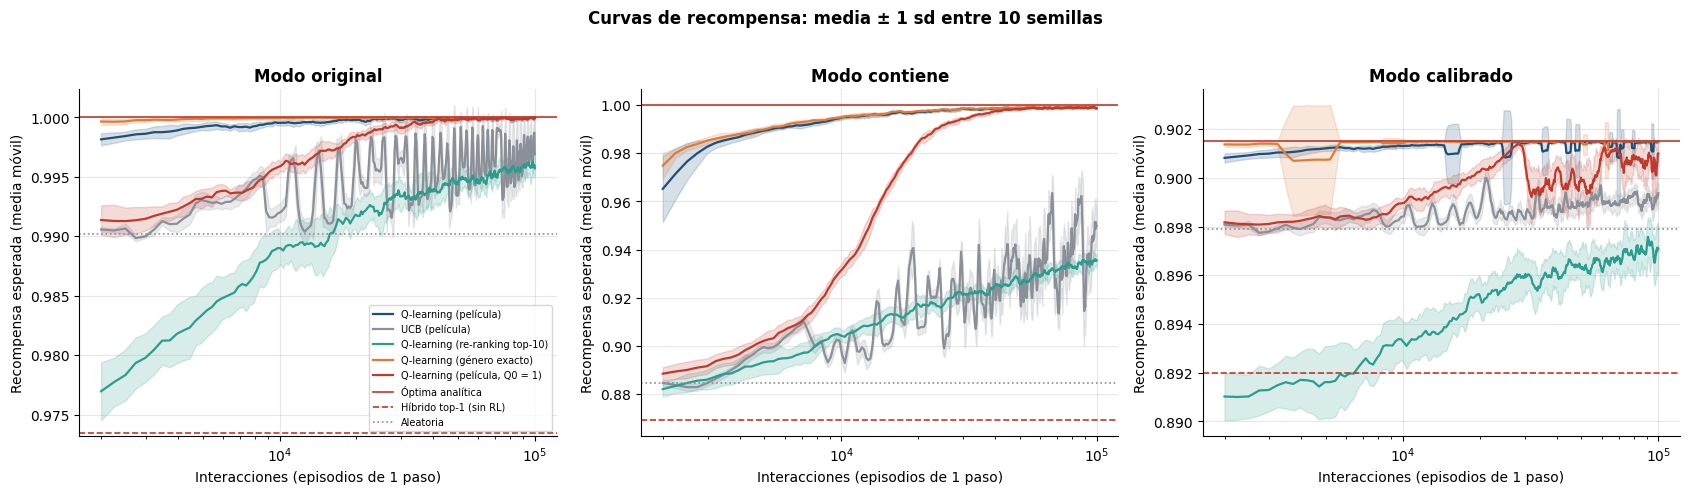

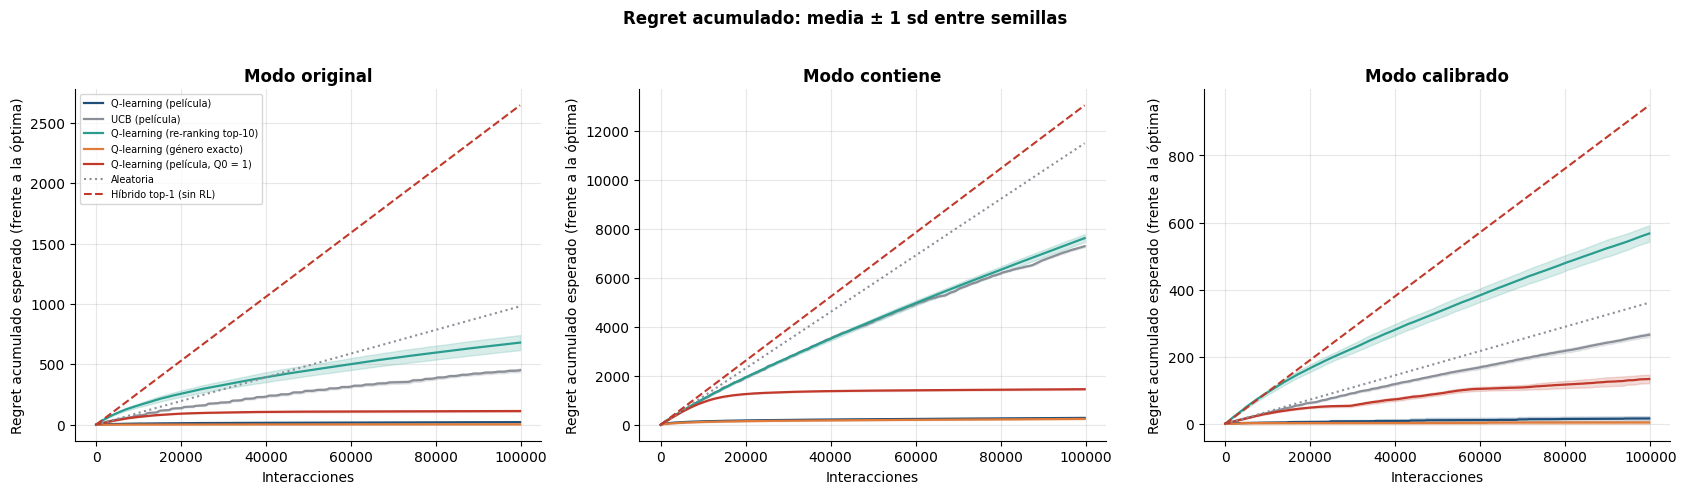

In [13]:
def _sub(x, paso):
    return x[..., ::paso]


with seccion("4_figuras_curvas"):
    estilos = {AGENTES[0]: PAL["principal"], AGENTES[1]: PAL["neutro"],
               AGENTES[2]: PAL["edad_youth"], AGENTES[3]: PAL["enfasis"], AGENTES[4]: PAL["referencia"]}
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
    for ax, m in zip(axs, R.MODOS):
        for ag in AGENTES:
            r = RES[m][ag][0]
            mm = R.media_movil(r["esperada"].astype(float), VENT_CURVA)
            t = np.arange(VENT_CURVA, T_FINAL + 1)
            paso = max(1, len(t) // 400)
            mu, sd = mm.mean(axis=0), mm.std(axis=0, ddof=1)
            ax.plot(_sub(t, paso), _sub(mu, paso), color=estilos[ag], label=ag, lw=1.6)
            ax.fill_between(_sub(t, paso), _sub(mu - sd, paso), _sub(mu + sd, paso),
                            color=estilos[ag], alpha=0.18)
        ax.axhline(VAL[m]["optimo"], color=PAL["referencia"], lw=1.2, label="Óptima analítica")
        ax.axhline(VAL[m]["hibrido_top1"], color=PAL["referencia"], lw=1.2, ls="--", label="Híbrido top-1 (sin RL)")
        ax.axhline(VAL[m]["azar"], color=PAL["neutro"], lw=1.2, ls=":", label="Aleatoria")
        ax.set_title(f"Modo {m}")
        ax.set_xlabel("Interacciones (episodios de 1 paso)")
        ax.set_ylabel("Recompensa esperada (media móvil)")
        ax.set_xscale("log")
    axs[0].legend(fontsize=7, loc="lower right")
    fig.suptitle(f"Curvas de recompensa: media ± 1 sd entre {len(SEMILLAS)} semillas", fontweight="bold", y=1.02)
    fig.tight_layout()
    plots.save_fig(fig, "04_curvas_recompensa")
    plt.show()

    fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
    for ax, m in zip(axs, R.MODOS):
        t = np.arange(1, T_FINAL + 1)
        paso = max(1, T_FINAL // 400)
        for ag in AGENTES:
            cum = np.cumsum(RES[m][ag][1], axis=1)
            mu, sd = cum.mean(axis=0), cum.std(axis=0, ddof=1)
            ax.plot(_sub(t, paso), _sub(mu, paso), color=estilos[ag], label=ag, lw=1.6)
            ax.fill_between(_sub(t, paso), _sub(mu - sd, paso), _sub(mu + sd, paso),
                            color=estilos[ag], alpha=0.18)
        ax.plot(_sub(t, paso), _sub(t * HORIZ[m], paso), color=PAL["neutro"], ls=":", label="Aleatoria")
        ax.plot(_sub(t, paso), _sub(t * (VAL[m]["optimo"] - VAL[m]["hibrido_top1"]), paso),
                color=PAL["referencia"], ls="--", label="Híbrido top-1 (sin RL)")
        ax.set_title(f"Modo {m}")
        ax.set_xlabel("Interacciones")
        ax.set_ylabel("Regret acumulado esperado (frente a la óptima)")
    axs[0].legend(fontsize=7, loc="upper left")
    fig.suptitle("Regret acumulado: media ± 1 sd entre semillas", fontweight="bold", y=1.02)
    fig.tight_layout()
    plots.save_fig(fig, "04_regret_acumulado")
    plt.show()

### 4.2 Mejora frente al recomendador estático (con IC 95 % entre semillas)

**Qué:** diferencia entre la recompensa final del agente y el valor exacto del híbrido top-1 y
de la aleatoria. El valor de los baselines es exacto (esperanza sobre la población de filas),
así que la incertidumbre del contraste es la de las semillas del agente (IC t de Student,
`n = nº de semillas`).

In [14]:
with seccion("4_mejora"):
    MEJORA = {}
    filas = []
    for m in R.MODOS:
        MEJORA[m] = {}
        for ag in AGENTES:
            rf = RESUMEN[m][ag]["recompensa_final"]
            for base_nombre, v in (("hibrido_top1", VAL[m]["hibrido_top1"]), ("azar", VAL[m]["azar"])):
                ic = R.ic_t(rf - v)
                MEJORA[m][f"{ag}|{base_nombre}"] = ic
            ic_h = MEJORA[m][f"{ag}|hibrido_top1"]
            ic_a = MEJORA[m][f"{ag}|azar"]
            filas.append({"modo": m, "agente": ag,
                          "Δ vs híbrido": f"{ic_h['valor']:+.4f} [{ic_h['ic95'][0]:+.4f}, {ic_h['ic95'][1]:+.4f}]",
                          "Δ vs aleatoria": f"{ic_a['valor']:+.4f} [{ic_a['ic95'][0]:+.4f}, {ic_a['ic95'][1]:+.4f}]"})
    print(pd.DataFrame(filas).to_string(index=False))

     modo                         agente               Δ vs híbrido             Δ vs aleatoria
 original          Q-learning (película) +0.0265 [+0.0264, +0.0265] +0.0098 [+0.0097, +0.0098]
 original                 UCB (película) +0.0237 [+0.0234, +0.0241] +0.0070 [+0.0067, +0.0074]
 original Q-learning (re-ranking top-10) +0.0224 [+0.0219, +0.0229] +0.0057 [+0.0053, +0.0062]
 original     Q-learning (género exacto) +0.0265 [+0.0265, +0.0265] +0.0098 [+0.0098, +0.0098]
 original  Q-learning (película, Q0 = 1) +0.0265 [+0.0264, +0.0265] +0.0098 [+0.0097, +0.0098]
 contiene          Q-learning (película) +0.1298 [+0.1296, +0.1299] +0.1142 [+0.1141, +0.1144]
 contiene                 UCB (película) +0.0787 [+0.0767, +0.0807] +0.0631 [+0.0611, +0.0651]
 contiene Q-learning (re-ranking top-10) +0.0662 [+0.0646, +0.0678] +0.0507 [+0.0491, +0.0523]
 contiene     Q-learning (género exacto) +0.1299 [+0.1298, +0.1300] +0.1143 [+0.1142, +0.1144]
 contiene  Q-learning (película, Q0 = 1) +0.1298 [

**Conclusión técnica.** "Mejor" significa que el IC 95 % de la diferencia excluye 0. El
Q-learning por película (config. elegida) mejora al híbrido en +0,0265 [0,0264; 0,0265] en
`original`, +0,130 en `contiene` y +0,0095 en `calibrado`, y a la aleatoria en +0,0098, +0,114 y
+0,0036 (todos con IC que excluyen 0). En `original` recupera casi toda la brecha posible (≈ 0,0098)
y su regret acumulado a 100.000 interacciones es ≈ 21 (aleatoria ≈ 983; híbrido ≈ 2.650); en
`contiene` ≈ 280 (frente a ≈ 11.530 y ≈ 13.085); en `calibrado` ≈ 16 (≈ 362 y ≈ 952). Los IC son
muy estrechos porque la política final es casi determinista (variabilidad mínima entre semillas),
no porque el resultado sea más fiable. **Re-ranking top-10:** mejora al híbrido, pero en
`calibrado` queda **por debajo de la aleatoria** (−0,0010 [−0,0016; −0,0005]): sólo puede escoger
entre los candidatos del híbrido, que son de por sí peores que el azar para youth (oráculo dentro
del top-10: 0,999 / 0,951 / 0,901). **UCB** (c = 1) explora demasiado con 1.000 brazos y converge
más lento. El agente **exploratorio** (`Q₀ = 1`) llega al mismo valor final con ≈ 5× más regret
(≈ 114 en `original`).

**Implicación de negocio:** aprender en línea reduce a una fracción las pérdidas del recomendador
actual, pero la ganancia absoluta en la tasa de visionado depende de cuán amplio sea el
segmento de riesgo (≈ 1 punto en `original`, ≈ 0,4 puntos con las tasas de los datos).

## 5. Convergencia y tiempo de descubrimiento

**Qué:** cuántas interacciones **del grupo de edad** necesita el agente (media ± sd entre
semillas; `(k/n)` = semillas que lo alcanzan):
- **(a) Evitar:** primera observación tras la cual la política **voraz determinista** (argmax,
  desempate fijo) no recomienda ninguna película de riesgo en ninguna observación posterior
  (se observa en una malla geométrica de 160 puntos).
- **(b) Identificar:** primera observación en que ≥ 90 % de las películas de riesgo del grupo
  tiene `Q` por debajo de la media de `Q` de las no penalizadas (y la variante 50 %).

**Por qué difieren:** (a) es casi inmediato en `original` porque el 91,3 % (youth) y el 98,7 %
(seniors) de los brazos ya son óptimos: casi cualquier película es segura (el "≈ 3" es el
primer punto de observación, es decir, una cota inferior de la resolución, no un tiempo
medido). (b) es lento porque hay que **probar cada película varias veces** (≈ 1.000 brazos por
contexto y la penalización sólo falla con prob. 0,3): aprender por película **no generaliza**.
El agente por **género exacto** (202 brazos) comparte la información entre las películas del
mismo género. Las interacciones son **del grupo**: las totales son ≈ 3× (un tercio de los
episodios cae en cada grupo).

In [15]:
with seccion("5_descubrimiento"):
    DESC = {}
    filas = []
    for m in R.MODOS:
        DESC[m] = {}
        for ag in (AGENTES[0], AGENTES[4], AGENTES[1], AGENTES[3]):
            r = RES[m][ag][0]
            td = R.tiempos_descubrimiento(r, 0.9)
            DESC[m][ag] = td
            for g, nombre in enumerate(R.GRUPOS):
                n_riesgo = (RES[m][ag][3]["riesgo"][g]).sum()
                if n_riesgo == 0:
                    continue
                filas.append({"modo": m, "agente": ag, "grupo": nombre, "brazos de riesgo": int(n_riesgo),
                              "(a) evitar": ms_t(td["evitar"][:, g]),
                              "(b) identificar 50 %": ms_t(td["identificar_50"][:, g]),
                              "(b) identificar 90 %": ms_t(td["identificar"][:, g])})
    TAB_DESC = pd.DataFrame(filas)
    print(TAB_DESC.to_string(index=False))
    print("\nConvergencia del criterio global (90 % de la brecha recuperada), en pasos totales:")
    for m in R.MODOS:
        print(f"  {m}: " + " | ".join(f"{ag}: {ms_t(RESUMEN[m][ag]['convergencia'])}" for ag in AGENTES))

     modo                        agente   grupo  brazos de riesgo             (a) evitar   (b) identificar 50 %   (b) identificar 90 %
 original         Q-learning (película)   youth                87          3 ± 1 (10/10)  24,436 ± 2,832 (2/10)    no alcanzado (0/10)
 original         Q-learning (película) seniors                13          3 ± 1 (10/10) 14,624 ± 10,644 (5/10)    no alcanzado (0/10)
 original Q-learning (película, Q0 = 1)   youth                87  1,907 ± 3,299 (10/10)    2,299 ± 203 (10/10)    7,547 ± 953 (10/10)
 original Q-learning (película, Q0 = 1) seniors                13          3 ± 1 (10/10)    2,945 ± 912 (10/10)  9,176 ± 2,125 (10/10)
 original                UCB (película)   youth                87      207 ± 619 (10/10)    2,016 ± 294 (10/10)  6,718 ± 1,118 (10/10)
 original                UCB (película) seniors                13          3 ± 1 (10/10)  3,249 ± 1,285 (10/10) 10,020 ± 2,221 (10/10)
 original    Q-learning (género exacto)   youth        

**Cuánto *sabe* el agente del segmento (separación de Q).** El regret mide lo que el agente
recomienda, no lo que sabe. Como complemento y control de especificidad (en `calibrado` también
fallan las películas seguras, así que "Q por debajo de la media" no discrimina por sí solo),
se calcula el AUC con que la `Q` final separa las películas de riesgo de las no penalizadas
**ya probadas** (0,5 = no distingue; 1 = separa perfectamente) y qué fracción del segmento llegó a probarse.

In [16]:
with seccion("5_separacion"):
    AUC_SEP, PROBADAS = {}, {}
    filas = []
    for m in R.MODOS:
        AUC_SEP[m], PROBADAS[m] = {}, {}
        for ag in (AGENTES[0], AGENTES[4], AGENTES[3]):
            r, _, Pm, po = RES[m][ag]
            a = R.auc_separacion(r["Q"], r["N"], po["riesgo"])
            AUC_SEP[m][ag] = a
            PROBADAS[m][ag] = {}
            for g, nombre in enumerate(R.GRUPOS):
                if not po["riesgo"][g].any():
                    continue
                pr = (r["N"][:, g, po["riesgo"][g]] > 0).mean(axis=1) * 100
                PROBADAS[m][ag][nombre] = pr
                filas.append({"modo": m, "agente": ag, "grupo": nombre,
                              "AUC de separación": ms(a[:, g], 3), "% del segmento probado": ms(pr, 1)})
    print(pd.DataFrame(filas).to_string(index=False))

     modo                        agente   grupo AUC de separación % del segmento probado
 original         Q-learning (película)   youth     0.701 ± 0.033             52.2 ± 5.1
 original         Q-learning (película) seniors     0.640 ± 0.072            53.1 ± 16.4
 original Q-learning (película, Q0 = 1)   youth     1.000 ± 0.000            100.0 ± 0.0
 original Q-learning (película, Q0 = 1) seniors     1.000 ± 0.000            100.0 ± 0.0
 original    Q-learning (género exacto)   youth     0.840 ± 0.184            100.0 ± 0.0
 original    Q-learning (género exacto) seniors     0.780 ± 0.174            100.0 ± 0.0
 contiene         Q-learning (película)   youth     0.704 ± 0.023             51.7 ± 1.2
 contiene         Q-learning (película)  adults     0.646 ± 0.023             52.7 ± 2.8
 contiene         Q-learning (película) seniors     0.678 ± 0.015             52.4 ± 1.5
 contiene Q-learning (película, Q0 = 1)   youth     1.000 ± 0.000            100.0 ± 0.0
 contiene Q-learning 

### 5.1 Política aprendida por grupo de edad

**Qué:** fila superior: `Q` final del agente **exploratorio** (`Q₀ = 1`, media entre semillas) para
las películas de **riesgo** y las **no penalizadas** de cada grupo, frente a la probabilidad
verdadera `P` (el agente de menor regret, con `Q₀` bajo, se queda con una película segura y
casi no explora, por lo que su `Q` apenas informa del resto). Fila inferior: porcentaje de las
recomendaciones acumuladas que cayeron en películas de riesgo, para el agente de menor regret
y para el exploratorio, frente al azar (porcentaje del catálogo que es de riesgo).

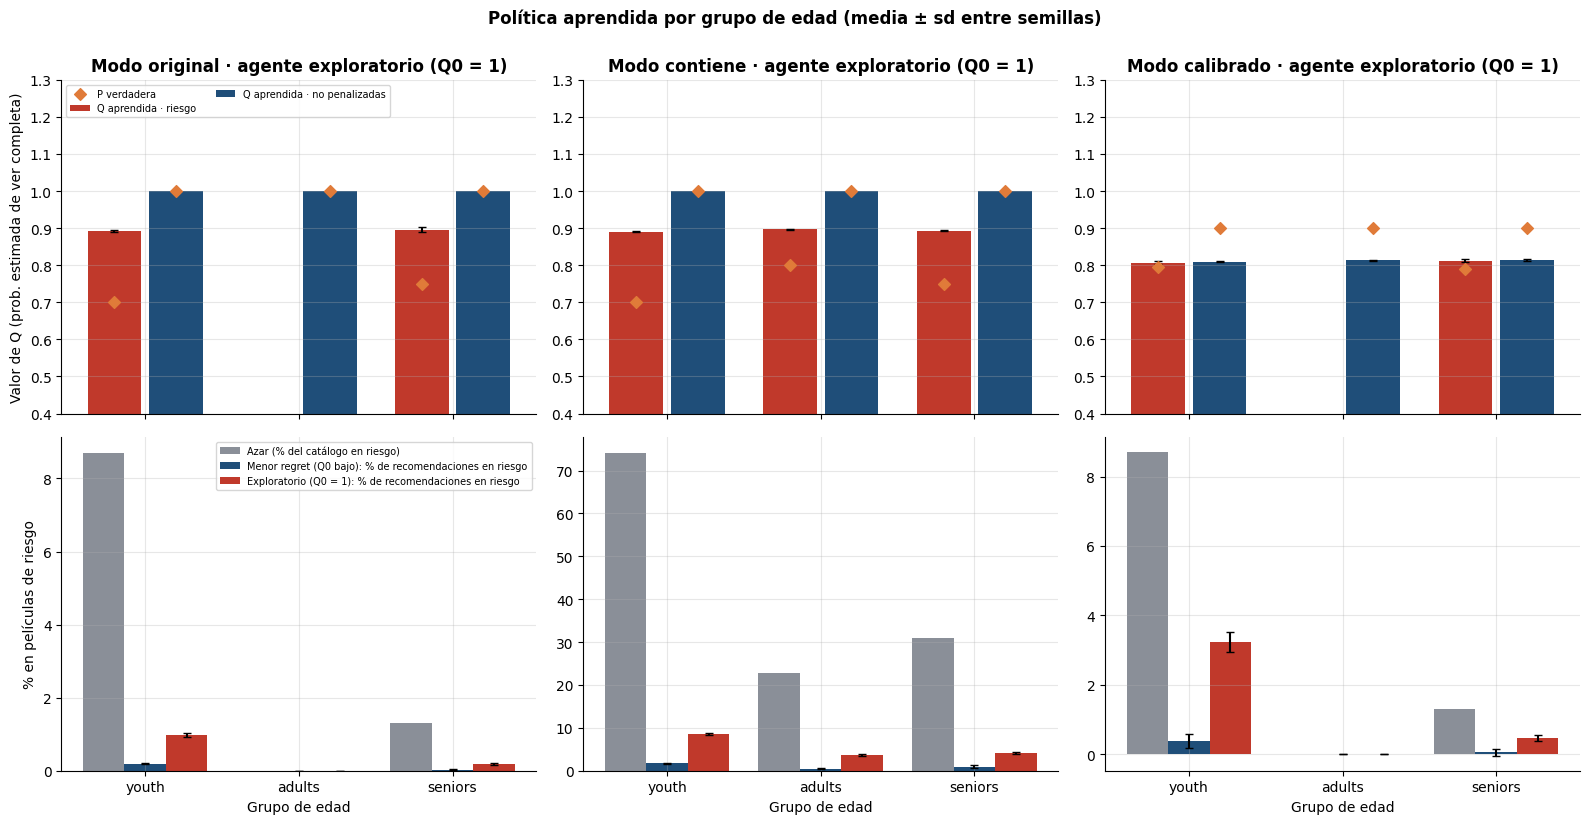

In [17]:
with seccion("5_figura_politica"), warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    fig, axs = plt.subplots(2, 3, figsize=(16, 8.2), sharex=True)
    for j, m in enumerate(R.MODOS):
        r, _, Pm, po = RES[m][AGENTES[4]]
        Q = r["Q"]
        riesgo = po["riesgo"]
        x = np.arange(3)
        qr = np.array([[Q[i, g, riesgo[g]].mean() if riesgo[g].any() else np.nan for g in range(3)]
                       for i in range(Q.shape[0])])
        qs = np.array([[Q[i, g, ~riesgo[g]].mean() if (~riesgo[g]).any() else np.nan for g in range(3)]
                       for i in range(Q.shape[0])])
        pr = [Pm[g, riesgo[g]].mean() if riesgo[g].any() else np.nan for g in range(3)]
        ps = [Pm[g, ~riesgo[g]].mean() if (~riesgo[g]).any() else np.nan for g in range(3)]
        ax = axs[0, j]
        ax.bar(x - 0.2, np.nanmean(qr, axis=0), 0.35, yerr=np.nanstd(qr, axis=0, ddof=1),
               color=PAL["referencia"], label="Q aprendida · riesgo", capsize=3)
        ax.bar(x + 0.2, np.nanmean(qs, axis=0), 0.35, yerr=np.nanstd(qs, axis=0, ddof=1),
               color=PAL["principal"], label="Q aprendida · no penalizadas", capsize=3)
        ax.scatter(x - 0.2, pr, marker="D", color=PAL["enfasis"], zorder=5, label="P verdadera")
        ax.scatter(x + 0.2, ps, marker="D", color=PAL["enfasis"], zorder=5)
        ax.set_ylim(0.4, 1.3)
        ax.set_title(f"Modo {m} · agente exploratorio (Q0 = 1)")
        if j == 0:
            ax.set_ylabel("Valor de Q (prob. estimada de ver completa)")
            ax.legend(fontsize=7, loc="upper left", ncol=2)
        ax = axs[1, j]
        cat_riesgo = [riesgo[g].mean() * 100 for g in range(3)]
        ax.bar(x - 0.27, cat_riesgo, 0.27, color=PAL["neutro"], label="Azar (% del catálogo en riesgo)")
        for k, (ag, col, et) in enumerate(((AGENTES[0], PAL["principal"], "Menor regret (Q0 bajo)"),
                                           (AGENTES[4], PAL["referencia"], "Exploratorio (Q0 = 1)"))):
            N = RES[m][ag][0]["N"]
            e = np.array([[N[i, g, riesgo[g]].sum() / max(N[i, g].sum(), 1) for g in range(3)]
                          for i in range(N.shape[0])]) * 100
            ax.bar(x + k * 0.27, e.mean(axis=0), 0.27, yerr=e.std(axis=0, ddof=1), color=col,
                   label=f"{et}: % de recomendaciones en riesgo", capsize=3)
        ax.set_xticks(x, R.GRUPOS)
        ax.set_xlabel("Grupo de edad")
        if j == 0:
            ax.set_ylabel("% en películas de riesgo")
            ax.legend(fontsize=7, loc="upper right")
    fig.suptitle("Política aprendida por grupo de edad (media ± sd entre semillas)", fontweight="bold", y=1.0)
    fig.tight_layout()
    plots.save_fig(fig, "04_politica_por_edad")
    plt.show()

**Conclusión técnica (ejecución completa).**
- **(a) Evitar el riesgo es rápido:** el agente de menor regret deja de recomendar el segmento en
  el primer punto observado (≈ 3 interacciones del grupo) en `original`; en `contiene` (74 % de las
  películas de youth penalizadas) tarda 32 ± 50 (youth) y 98 ± 150 (seniors).
- **(b) Identificarlo es lento y requiere explorar:** el agente de menor regret prueba sólo el
  ≈ 52 % del segmento y su `Q` lo separa con AUC ≈ 0,70 (youth) y ≈ 0,64 (seniors) en `original`:
  *actúa* bien sin *saber*. El exploratorio (`Q₀ = 1`) sí lo aprende: AUC = 1,0, 50 % del segmento
  en ≈ 2.300 (youth) y ≈ 2.900 (seniors) interacciones del grupo, y 90 % en ≈ 7.500 y ≈ 9.200
  (≈ 22.600 y ≈ 27.500 interacciones totales). A cambio, su regret es ≈ 5× mayor.
- **Generalizar ayuda:** el agente por género exacto identifica la mitad del segmento de youth en
  ≈ 330 interacciones (frente a ≈ 2.300 por película), aunque al 90 % es ruidoso (4.110 ± 5.658;
  9/10) porque Horror son 2 películas y casi nunca se prueba.
- **En `calibrado` (tasas de los datos) el segmento NO se aprende con este presupuesto:** la `Q`
  por película separa con AUC ≈ 0,51-0,57 (≈ azar) incluso explorando todo, y por género
  ≈ 0,69 ± 0,21 (youth). El criterio "Q por debajo de la media" no es específico allí (las
  películas seguras también fallan ≈ 10 %), por lo que los tiempos (b) de `calibrado` NO deben
  leerse como descubrimiento; vale el AUC. El regret del agente de menor regret es bajo (≈ 16)
  porque encuentra *una* película segura, no porque conozca el segmento.

**Implicación de negocio:** evitar el segmento de riesgo se aprende casi de inmediato, pero
*saber* cuál es exige miles de interacciones por grupo si se explora película a película; con
las tasas de abandono reales (penalización ≈ 0,11 sobre una base ≈ 0,10) no se llegaría a saberlo
en 100.000 interacciones, de modo que conviene representar por género y edad.

## 6. Narrativa de cierre

**Qué aprende el agente.** Con una recompensa de un paso y un solo contexto (edad), el agente
aprende a no recomendar el segmento **youth × Drama/Horror exactos y seniors × Comedy exacto**;
adults nunca se penaliza porque no hay películas con `Genre` exactamente `Action`, `Sci-Fi` o
`Romance`. Es **el mismo segmento (edad × género puro)** que el Random Forest del reto 3
detectaba offline con ROC-AUC 0,523 (señal diminuta en edad × género). La diferencia es el
camino: el RF lo hace con features y datos históricos y con señal débil; el agente lo aprende
por ensayo y error.

**Cuánto tarda.** Evitar el segmento: ≈ 3 interacciones del grupo en `original` (cota de
resolución). Identificarlo (≥ 50 % de las películas de riesgo con `Q` menor): ≈ 2.300 (youth) y
≈ 2.900 (seniors) interacciones del grupo con el agente exploratorio, ≈ 7.500-9.200 al 90 %; el
de menor regret casi no llega (2/10 y 5/10 semillas al 50 %). Convergencia del criterio global:
≈ 3.900 pasos (menor regret) frente a ≈ 22.200 (exploratorio) en `original`.

**Mejora frente al recomendador estático.** Recompensa final +0,0265 [0,0264; 0,0265] sobre el
híbrido en `original` (+0,0098 sobre el azar), +0,130 en `contiene` y +0,0095 en `calibrado`
(+0,0036 sobre el azar); regret acumulado 21,5 ± 0,9 frente a 2.650 del híbrido a 100.000
interacciones. En `original` la ganancia **absoluta es pequeña** (≈ 1 punto de probabilidad de
visionado) porque el segmento afecta a ≈ 9 % de las películas de youth y a ≈ 1 % de las de seniors.

**Por qué el aprendizaje en línea.** El histórico no revela preferencias de elección (notebook 00,
*Estructura de preferencias*): las interacciones son lo que ya se mostró, no lo que el usuario
habría elegido. Aprender recomendando y observando el desenlace es la vía para obtener esa
información; el costo es exponer a usuarios reales a recomendaciones de riesgo mientras se explora.

**Límites.** (1) El simulador no es el mundo real: 0 % de abandono fuera del segmento y
penalización 0,30/0,25 frente a ≈ 10 % y ≈ 0,21 observados; con las tasas reales el problema es
≈ 3× menos detectable y el segmento no se aprende (AUC de `Q` ≈ azar). (2) Recompensa binaria de
un paso, sin efectos de largo plazo (satisfacción, retención, fatiga por repetir la misma
película). (3) La política de menor regret es degenerada (una película por grupo) porque la
recompensa no premia diversidad; sólo tiene sentido como veto sobre otro recomendador. (4) El
estado es sólo la edad; no hay personalización por usuario. (5) Los baselines son valores
esperados exactos de la población de filas del entorno; los IC reflejan la variabilidad entre
semillas del agente, no la de muestrear usuarios. (6) Se omite el DQN (con 3 estados el caso
tabular es exacto). (7) Las reglas del simulador se conocen: el óptimo analítico es una
referencia, no un objetivo alcanzable con datos reales.

**Conclusión técnica.** Con la regla exacta del profesor, Q-learning tabular (ε inverso,
α = 0,1, `Q₀ = 0,5`) llega a un regret de 21,5 en 100.000 interacciones frente a 982,5 del azar
y 2.650,5 del híbrido, y a una recompensa final de 0,99995; evitar el segmento es inmediato,
pero identificarlo exige miles de interacciones por grupo con exploración optimista y, con las
tasas de los datos (`calibrado`), no se aprende (AUC de `Q` ≈ 0,5). La ganancia absoluta es pequeña
(+0,0098 sobre el azar en `original`) y el agente de menor regret es degenerado.
**Implicación de negocio:** un recomendador que aprende en línea evita el segmento de riesgo
casi de inmediato y supera al recomendador estático (+0,0265 de probabilidad de visionado
completo), pero la ganancia es pequeña y conocer el segmento exige explorar con usuarios reales.

## 7. Métricas (JSON) y ficha del modelo

In [18]:
metricas = {}
for ag, clave in ((AGENTES[0], "qlearning"), (AGENTES[2], "reranking"), (AGENTES[3], "genero")):
    for m in R.MODOS:
        d = RESUMEN[m][ag]
        metricas[f"{clave}_recompensa_final_{m}"] = R.ic_t(d["recompensa_final"])
        metricas[f"{clave}_regret_acumulado_{m}"] = R.ic_t(d["regret_acum"])
        if "valor_voraz_final" in d:
            metricas[f"{clave}_valor_voraz_final_{m}"] = R.ic_t(d["valor_voraz_final"])
for m in R.MODOS:
    for base_nombre in ("hibrido_top1", "azar"):
        metricas[f"mejora_qlearning_vs_{base_nombre}_{m}"] = MEJORA[m][f"{AGENTES[0]}|{base_nombre}"]

por_modo = {}
for m in R.MODOS:
    por_modo[m] = {
        "peliculas_a_evitar": dict(zip(R.GRUPOS, VAL[m]["n_evitar"])),
        "valores_esperados_exactos": {k: VAL[m][k] for k in
                                      ("azar", "hibrido_top1", "hibrido_topk_medio", "oraculo_topk", "optimo", "brecha")},
        "azar_por_grupo": dict(zip(R.GRUPOS, VAL[m]["azar_por_grupo"])),
        "hibrido_top1_por_grupo": dict(zip(R.GRUPOS, VAL[m]["hibrido_top1_por_grupo"])),
        "agentes": {
            ag: {
                "recompensa_final": R.ic_t(RESUMEN[m][ag]["recompensa_final"]),
                "recompensa_real_final": R.ic_t(RESUMEN[m][ag]["recompensa_real_final"]),
                "regret_acumulado": R.ic_t(RESUMEN[m][ag]["regret_acum"]),
                "valor_voraz_final": (R.ic_t(RESUMEN[m][ag]["valor_voraz_final"])
                                      if "valor_voraz_final" in RESUMEN[m][ag] else None),
                "convergencia_pasos": {"media": float(np.nanmean(RESUMEN[m][ag]["convergencia"])) if
                                       (~np.isnan(RESUMEN[m][ag]["convergencia"])).any() else None,
                                       "sd": float(np.nanstd(RESUMEN[m][ag]["convergencia"], ddof=1)) if
                                       (~np.isnan(RESUMEN[m][ag]["convergencia"])).sum() > 1 else None,
                                       "semillas_que_convergen": int((~np.isnan(RESUMEN[m][ag]["convergencia"])).sum())},
            } for ag in AGENTES},
        "descubrimiento_interacciones_del_grupo": {
            ag: {g: {k: ({"media": float(np.nanmean(DESC[m][ag][k][:, i])),
                          "sd": float(np.nanstd(DESC[m][ag][k][:, i], ddof=1)) if (~np.isnan(DESC[m][ag][k][:, i])).sum() > 1 else 0.0,
                          "semillas_que_lo_alcanzan": int((~np.isnan(DESC[m][ag][k][:, i])).sum())}
                         if (~np.isnan(DESC[m][ag][k][:, i])).any()
                         else {"media": None, "sd": None, "semillas_que_lo_alcanzan": 0})
                     for k in ("evitar", "identificar_50", "identificar")}
                 for i, g in enumerate(R.GRUPOS) if RES[m][ag][3]["riesgo"][i].any()}
            for ag in (AGENTES[0], AGENTES[4], AGENTES[1], AGENTES[3])},
    }

resultado = {
    "modo": MODO,
    "config": {
        "semillas_evaluacion": SEMILLAS, "semillas_ajuste": SEM_AJUSTE, "semilla_global": SEED,
        "problema": "bandit contextual, episodios de 1 paso (gamma irrelevante)",
        "estado": "grupo de edad (youth, adults, seniors)",
        "acciones": "pelicula (1.000 brazos), top-10 del hibrido (re-ranking) y genero exacto (202 brazos)",
        "n_episodios": T_FINAL, "n_episodios_ajuste": T_AJUSTE,
        "hiperparametros": {**CFG, "actualizacion": "Q[s,a] += alpha*(r - Q[s,a])"},
        "espacio_de_busqueda": {"epsilon": [f"constante ({CFG['eps0']})", "exponencial", "inverso"],
                                "alpha": [0.1, "1/N"], "q0": [1.0, 0.5, 0.0]},
        "ajuste": AJ.to_dict(orient="records"),
        "criterio_convergencia": f"media movil del regret (ventana {VENT_CURVA}) <= 10 % del regret de la politica aleatoria",
        "criterio_descubrimiento": "(a) politica voraz sin riesgo de forma estable; (b) >= 90 % (y 50 %) de las "
                                   "peliculas de riesgo con Q < media de Q de las no penalizadas",
        "ventana_recompensa_final": VENT_FINAL, "recomendador_hibrido": {"alpha": ALPHA_H, "positivo": POSITIVO_H, "k": K_RERANK,
                                                 "fuente": FUENTE_H,
                                                 "top1_drama_exacto_pct": HIB_DRAMA},
        "calibracion_modo_calibrado": CALIB,
        "ic95": "t de Student entre semillas (n = nº de semillas)",
        "dqn": "omitido: con 3 estados el caso tabular es exacto (primer escalon de la politica de plazo)",
        "versiones": {"numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
                      "python": sys.version.split()[0]},
    },
    "baseline": {
        "nombre": "politica aleatoria (valor esperado exacto) y recomendador hibrido top-1 sin RL",
        "metricas": {m: {"aleatoria": VAL[m]["azar"], "hibrido_top1": VAL[m]["hibrido_top1"],
                         "optimo": VAL[m]["optimo"]} for m in R.MODOS},
    },
    "metricas": metricas,
    "por_modo": por_modo,
    "separacion_q": {m: {ag: {g: R.ic_t(AUC_SEP[m][ag][:, i]) for i, g in enumerate(R.GRUPOS)
                              if RES[m][ag][3]["riesgo"][i].any()} for ag in AUC_SEP[m]} for m in R.MODOS},
    "segmento_probado_pct": {m: {ag: {g: R.ic_t(v) for g, v in PROBADAS[m][ag].items()} for ag in PROBADAS[m]}
                             for m in R.MODOS},
    "simulador_vs_datos": TAB_SIM.to_dict(orient="records"),
    "tiempos_seccion_s": TIEMPOS,
}
ruta = RAIZ / "reports" / "metrics" / "rl.json"
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(resultado, indent=2, ensure_ascii=False, default=nativo), encoding="utf-8")
print("Guardado: reports/metrics/rl.json")
print(f"Tiempo total de las secciones medidas: {sum(TIEMPOS.values()):.0f} s")
print(TIEMPOS)

Guardado: reports/metrics/rl.json
Tiempo total de las secciones medidas: 274 s
{'1_entorno': 0.1, '1_entorno_nile': 0.0, '1_simulador_vs_datos': 0.3, '2_modos_y_baselines': 1.0, '2_montecarlo': 33.9, '2_figura_entorno': 0.6, '3_ajuste': 104.3, '4_entrenamiento': 131.2, '4_resumen': 0.2, '4_figuras_curvas': 1.7, '4_mejora': 0.0, '5_descubrimiento': 0.0, '5_separacion': 0.0, '5_figura_politica': 0.8}


### Ficha del modelo

| Campo | Contenido |
|---|---|
| **Propósito** | Descubrir en línea qué combinaciones edad × película evitar y cuantificar el aprendizaje frente a un recomendador estático. Ejercicio sobre un **simulador**; no es un sistema desplegable. |
| **Modelo** | Q-learning tabular ε-greedy (ε inverso 0,3 → 0,01 a mitad del entrenamiento, α = 0,1, `Q₀ = 0,5`, γ irrelevante) en un bandit contextual de episodios de 1 paso; estado = grupo de edad (3); acciones = película (1.000), top-10 del híbrido o género exacto (202). Referencias: UCB1 (c = 1) y agente exploratorio (`Q₀ = 1`). Sin DQN. |
| **Datos / entorno** | `NilePrimeEnv` (hereda de `SimulationEnvironment`, sin modificar `agent.py`); 1.000 películas y 100.623 interacciones (estado = fila muestreada). Tres modos: `original` (regla exacta), `contiene` y `calibrado`. |
| **Métricas (10 semillas, 100.000 interacciones, IC 95 % t entre semillas)** | `original`: recompensa final 0,99995 [0,99991; 0,99999], regret acumulado 21,5 [20,8; 22,1] (aleatoria 982,5; híbrido 2.650,5; óptima 0). Mejora sobre el híbrido +0,0265 [0,0264; 0,0265]; sobre la aleatoria +0,0098. `contiene`: regret 280 (aleatoria 11.530); `calibrado`: regret 16 (aleatoria 362), mejora sobre la aleatoria +0,0036. |
| **Convergencia / descubrimiento** | Criterio: 90 % de la brecha azar-óptimo en ventana de 2.000 pasos; ≈ 3.900 pasos (menor regret) y ≈ 22.200 (exploratorio) en `original`. Evitar el segmento ≈ 3 interacciones del grupo; identificar ≥ 50 % del segmento ≈ 2.300 (youth) con el exploratorio. |
| **Costo operativo** | Entrenamiento ≈ 50 µs por interacción vectorizando semillas (≈ 130 s las 15 corridas finales de 10 semillas × 100.000); inferencia = `argmax` sobre 1.000 valores (µs); tamaño de Q: 3 × 1.000 float64 ≈ 24 KB por semilla. |
| **Limitaciones y riesgos** | Simulador ≠ mundo real (0 % de abandono base, penalizaciones 0,30/0,25 frente a ≈ 0,21); recompensa binaria de un paso, sin largo plazo; la política de menor regret es degenerada (una película por grupo) y no sabe qué es el segmento; con las tasas realistas (`calibrado`) el segmento no se aprende (AUC de Q ≈ 0,5); explorar con usuarios reales tiene costo; IC estrechos por política casi determinista; baselines exactos (sin incertidumbre de muestreo de usuarios). |
| **Uso previsto / no previsto** | Previsto: comparar estrategias de exploración y estimar cuánto tardaría en aprenderse un segmento de riesgo. No previsto: estimar la retención real ni sustituir un recomendador personalizado. |